# Bangla License Plate Deblurring - Pix2Pix Baseline
Conditional GAN: U-Net generator with skip connections and a PatchGAN discriminator that sees the blurry and the sharp image together. Trained with adversarial loss + 100 x L1 loss, same data and same image size as the other models so the comparison stays fair.

## Libraries

In [1]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

device = torch.device("cuda")
torch.backends.cudnn.benchmark = True
print("GPU:", torch.cuda.get_device_name(0))

d:\_deblur gan\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GPU: NVIDIA GeForce RTX 3060


## Paths and settings

In [4]:
CLEAN_DIR = r"D:\_deblur gan\new dataset\fixed cropped"
GAUSSIAN_DIR = r"D:\_deblur gan\new dataset\light_gaussian_blurred"
MOTION_DIR = r"D:\_deblur gan\new dataset\light_motion_blurred"

IMG_H = 128
IMG_W = 256
BATCH_SIZE = 16
EPOCHS = 20
LR = 2e-4
VAL_SPLIT = 0.1
SEED = 42

L1_WEIGHT = 100

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

## Dataset (images are loaded into RAM once, so training is faster)

In [5]:
valid_ext = (".png", ".jpg", ".jpeg", ".bmp")

clean_names = sorted([f for f in os.listdir(CLEAN_DIR) if f.lower().endswith(valid_ext)])
random.shuffle(clean_names)

val_count = int(len(clean_names) * VAL_SPLIT)
val_names = clean_names[:val_count]
train_names = clean_names[val_count:]


def make_pairs(names):
    pairs = []
    for name in names:
        for blur_dir in (GAUSSIAN_DIR, MOTION_DIR):
            blur_path = os.path.join(blur_dir, name)
            if os.path.exists(blur_path):
                pairs.append((blur_path, os.path.join(CLEAN_DIR, name)))
    return pairs


class PlateDataset(Dataset):
    def __init__(self, pairs):
        self.blur = []
        self.clean = []
        for blur_path, clean_path in tqdm(pairs):
            self.blur.append(self.load(blur_path))
            self.clean.append(self.load(clean_path))

    def __len__(self):
        return len(self.blur)

    def load(self, path):
        img = Image.open(path).convert("RGB").resize((IMG_W, IMG_H), Image.BICUBIC)
        return torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1)

    def __getitem__(self, i):
        return self.blur[i].float() / 127.5 - 1, self.clean[i].float() / 127.5 - 1


train_pairs = make_pairs(train_names)
val_pairs = make_pairs(val_names)

train_loader = DataLoader(PlateDataset(train_pairs), batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True, drop_last=True)
val_loader = DataLoader(PlateDataset(val_pairs), batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print("clean images:", len(clean_names))
print("train pairs:", len(train_pairs))
print("val pairs:", len(val_pairs))

100%|██████████| 398/398 [00:09<00:00, 42.21it/s]

clean images: 1991
train pairs: 3584
val pairs: 398


## Generator blocks

In [6]:
class DownBlock(nn.Module):
    def __init__(self, in_ch, out_ch, norm=True):
        super().__init__()
        layers = [nn.Conv2d(in_ch, out_ch, 4, 2, 1, bias=False)]
        if norm:
            layers.append(nn.BatchNorm2d(out_ch))
        layers.append(nn.LeakyReLU(0.2, True))
        self.body = nn.Sequential(*layers)

    def forward(self, x):
        return self.body(x)


class UpBlock(nn.Module):
    def __init__(self, in_ch, out_ch, dropout=False):
        super().__init__()
        layers = [
            nn.ConvTranspose2d(in_ch, out_ch, 4, 2, 1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(True),
        ]
        if dropout:
            layers.append(nn.Dropout(0.5))
        self.body = nn.Sequential(*layers)

    def forward(self, x, skip):
        return torch.cat([self.body(x), skip], dim=1)

## Generator (U-Net)

In [7]:
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.d1 = DownBlock(3, 64, norm=False)
        self.d2 = DownBlock(64, 128)
        self.d3 = DownBlock(128, 256)
        self.d4 = DownBlock(256, 512)
        self.d5 = DownBlock(512, 512)
        self.d6 = DownBlock(512, 512)
        self.d7 = DownBlock(512, 512, norm=False)

        self.u1 = UpBlock(512, 512, dropout=True)
        self.u2 = UpBlock(1024, 512, dropout=True)
        self.u3 = UpBlock(1024, 512, dropout=True)
        self.u4 = UpBlock(1024, 256)
        self.u5 = UpBlock(512, 128)
        self.u6 = UpBlock(256, 64)

        self.final = nn.Sequential(
            nn.ConvTranspose2d(128, 3, 4, 2, 1),
            nn.Tanh(),
        )

    def forward(self, x):
        d1 = self.d1(x)
        d2 = self.d2(d1)
        d3 = self.d3(d2)
        d4 = self.d4(d3)
        d5 = self.d5(d4)
        d6 = self.d6(d5)
        d7 = self.d7(d6)

        y = self.u1(d7, d6)
        y = self.u2(y, d5)
        y = self.u3(y, d4)
        y = self.u4(y, d3)
        y = self.u5(y, d2)
        y = self.u6(y, d1)
        return self.final(y)

## Discriminator (conditional PatchGAN)

In [8]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        def block(in_ch, out_ch, stride, norm=True):
            layers = [nn.Conv2d(in_ch, out_ch, 4, stride, 1, bias=False)]
            if norm:
                layers.append(nn.BatchNorm2d(out_ch))
            layers.append(nn.LeakyReLU(0.2, True))
            return layers

        self.net = nn.Sequential(
            *block(6, 64, 2, norm=False),
            *block(64, 128, 2),
            *block(128, 256, 2),
            *block(256, 512, 1),
            nn.Conv2d(512, 1, 4, 1, 1),
        )

    def forward(self, blur, img):
        return self.net(torch.cat([blur, img], dim=1))

## Loss functions and metrics (PSNR, SSIM, MAE)

In [9]:
gan_loss = nn.BCEWithLogitsLoss()


def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)


def ssim(fake, real, window=11, sigma=1.5):
    fake = (fake.clamp(-1, 1) + 1) / 2
    real = (real + 1) / 2
    coords = torch.arange(window, dtype=torch.float32, device=fake.device) - window // 2
    g = torch.exp(-(coords ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    kernel = (g[:, None] * g[None, :]).expand(3, 1, window, window).contiguous()
    mu_f = F.conv2d(fake, kernel, groups=3)
    mu_r = F.conv2d(real, kernel, groups=3)
    var_f = F.conv2d(fake * fake, kernel, groups=3) - mu_f ** 2
    var_r = F.conv2d(real * real, kernel, groups=3) - mu_r ** 2
    cov = F.conv2d(fake * real, kernel, groups=3) - mu_f * mu_r
    c1 = 0.01 ** 2
    c2 = 0.03 ** 2
    score = ((2 * mu_f * mu_r + c1) * (2 * cov + c2)) / ((mu_f ** 2 + mu_r ** 2 + c1) * (var_f + var_r + c2))
    return score.mean(dim=(1, 2, 3))


def mae(fake, real):
    return ((fake.clamp(-1, 1) - real).abs() * 127.5).mean(dim=(1, 2, 3))


def evaluate(net, loader):
    net.eval()
    p_all, s_all, m_all = [], [], []
    with torch.no_grad():
        for blur, clean in loader:
            blur = blur.to(device)
            clean = clean.to(device)
            fake = net(blur)
            if isinstance(fake, (list, tuple)):
                fake = fake[0]
            fake = fake.clamp(-1, 1)
            mse = (((fake + 1) / 2 - (clean + 1) / 2) ** 2).mean(dim=(1, 2, 3))
            p_all.append(10 * torch.log10(1 / (mse + 1e-8)))
            s_all.append(ssim(fake, clean))
            m_all.append(mae(fake, clean))
    return torch.cat(p_all), torch.cat(s_all), torch.cat(m_all)

## Models and optimizers

In [10]:
G = Generator().to(device)
D = Discriminator().to(device)
G.apply(init_weights)
D.apply(init_weights)

opt_g = torch.optim.Adam(G.parameters(), lr=LR, betas=(0.5, 0.999))
opt_d = torch.optim.Adam(D.parameters(), lr=LR, betas=(0.5, 0.999))

print("generator params:", sum(p.numel() for p in G.parameters()) / 1e6, "M")
print("discriminator params:", sum(p.numel() for p in D.parameters()) / 1e6, "M")

generator params: 41.828995 M
discriminator params: 2.768641 M


## Blurry input metrics (reference before training)

In [11]:
p, s, m = evaluate(nn.Identity(), val_loader)
print(f"Blurry input | PSNR {p.mean():.2f} | SSIM {s.mean():.4f} | MAE {m.mean():.2f}")

Blurry input | PSNR 26.27 | SSIM 0.8171 | MAE 9.01


## Checkpoint setup

In [12]:
CKPT_DIR = "checkpoints_pix2pix"
os.makedirs(CKPT_DIR, exist_ok=True)
LAST_PATH = os.path.join(CKPT_DIR, "last.pth")
BEST_PATH = os.path.join(CKPT_DIR, "best.pth")

start_epoch = 0
best_psnr = 0.0
history = {"g_loss": [], "d_loss": [], "val_psnr": [], "val_ssim": [], "val_mae": []}

RESUME = False

if RESUME and os.path.exists(LAST_PATH):
    ckpt = torch.load(LAST_PATH, map_location=device)
    G.load_state_dict(ckpt["G"])
    D.load_state_dict(ckpt["D"])
    opt_g.load_state_dict(ckpt["opt_g"])
    opt_d.load_state_dict(ckpt["opt_d"])
    history = ckpt["history"]
    best_psnr = ckpt["best_psnr"]
    start_epoch = ckpt["epoch"] + 1
    print("resumed from epoch", start_epoch)

## Training

In [13]:
for epoch in range(start_epoch, EPOCHS):
    G.train()
    D.train()
    g_sum = 0
    d_sum = 0

    for blur, clean in tqdm(train_loader, desc=f"Epoch {epoch + 1}/{EPOCHS}"):
        blur = blur.to(device, non_blocking=True)
        clean = clean.to(device, non_blocking=True)

        fake = G(blur)

        opt_d.zero_grad()
        d_real = D(blur, clean)
        d_fake = D(blur, fake.detach())
        d_loss = 0.5 * (gan_loss(d_real, torch.ones_like(d_real)) + gan_loss(d_fake, torch.zeros_like(d_fake)))
        d_loss.backward()
        opt_d.step()

        opt_g.zero_grad()
        d_out = D(blur, fake)
        adv = gan_loss(d_out, torch.ones_like(d_out))
        l1 = F.l1_loss(fake, clean)
        g_loss = adv + L1_WEIGHT * l1
        g_loss.backward()
        opt_g.step()

        g_sum += g_loss.item()
        d_sum += d_loss.item()

    p, s, m = evaluate(G, val_loader)
    val_psnr = p.mean().item()
    val_ssim = s.mean().item()
    val_mae = m.mean().item()

    history["g_loss"].append(g_sum / len(train_loader))
    history["d_loss"].append(d_sum / len(train_loader))
    history["val_psnr"].append(val_psnr)
    history["val_ssim"].append(val_ssim)
    history["val_mae"].append(val_mae)

    print(f"epoch {epoch + 1} | G loss {history['g_loss'][-1]:.4f} | D loss {history['d_loss'][-1]:.4f} | val PSNR {val_psnr:.2f} | SSIM {val_ssim:.4f} | MAE {val_mae:.2f}")

    if history["val_psnr"][-1] > best_psnr:
        best_psnr = history["val_psnr"][-1]
        torch.save(G.state_dict(), BEST_PATH)

    torch.save({
        "G": G.state_dict(),
        "D": D.state_dict(),
        "opt_g": opt_g.state_dict(),
        "opt_d": opt_d.state_dict(),
        "history": history,
        "best_psnr": best_psnr,
        "epoch": epoch,
    }, LAST_PATH)

Epoch 1/20: 100%|██████████| 224/224 [00:34<00:00,  6.50it/s]


epoch 1 | G loss 13.9635 | D loss 0.6240 | val PSNR 23.88 | SSIM 0.7351 | MAE 11.97


Epoch 2/20: 100%|██████████| 224/224 [00:27<00:00,  8.28it/s]


epoch 2 | G loss 11.0163 | D loss 0.5360 | val PSNR 24.37 | SSIM 0.7498 | MAE 11.54


Epoch 3/20: 100%|██████████| 224/224 [00:27<00:00,  8.21it/s]


...

epoch 18 | G loss 9.8141 | D loss 0.2123 | val PSNR 27.10 | SSIM 0.8406 | MAE 8.15


Epoch 19/20: 100%|██████████| 224/224 [00:29<00:00,  7.55it/s]


epoch 19 | G loss 9.7012 | D loss 0.2835 | val PSNR 27.32 | SSIM 0.8477 | MAE 7.80


Epoch 20/20: 100%|██████████| 224/224 [00:29<00:00,  7.57it/s]


epoch 20 | G loss 9.9387 | D loss 0.1738 | val PSNR 26.14 | SSIM 0.8129 | MAE 8.99


## Training curves

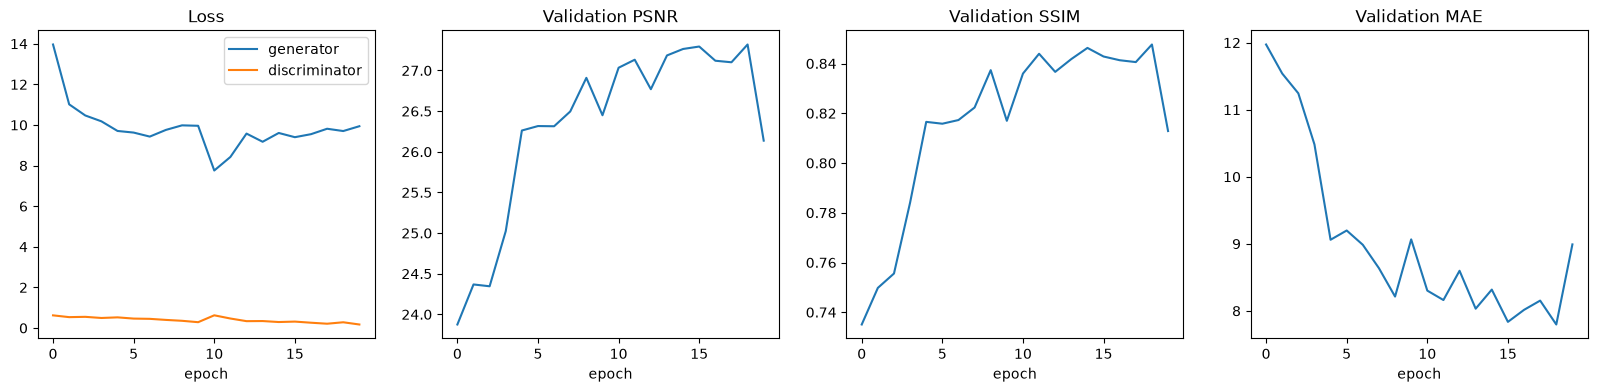

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].plot(history["g_loss"], label="generator")
axes[0].plot(history["d_loss"], label="discriminator")
axes[0].set_title("Loss")
axes[0].legend()
axes[1].plot(history["val_psnr"])
axes[1].set_title("Validation PSNR")
axes[2].plot(history["val_ssim"])
axes[2].set_title("Validation SSIM")
axes[3].plot(history["val_mae"])
axes[3].set_title("Validation MAE")
for ax in axes:
    ax.set_xlabel("epoch")
plt.show()

## Visual results

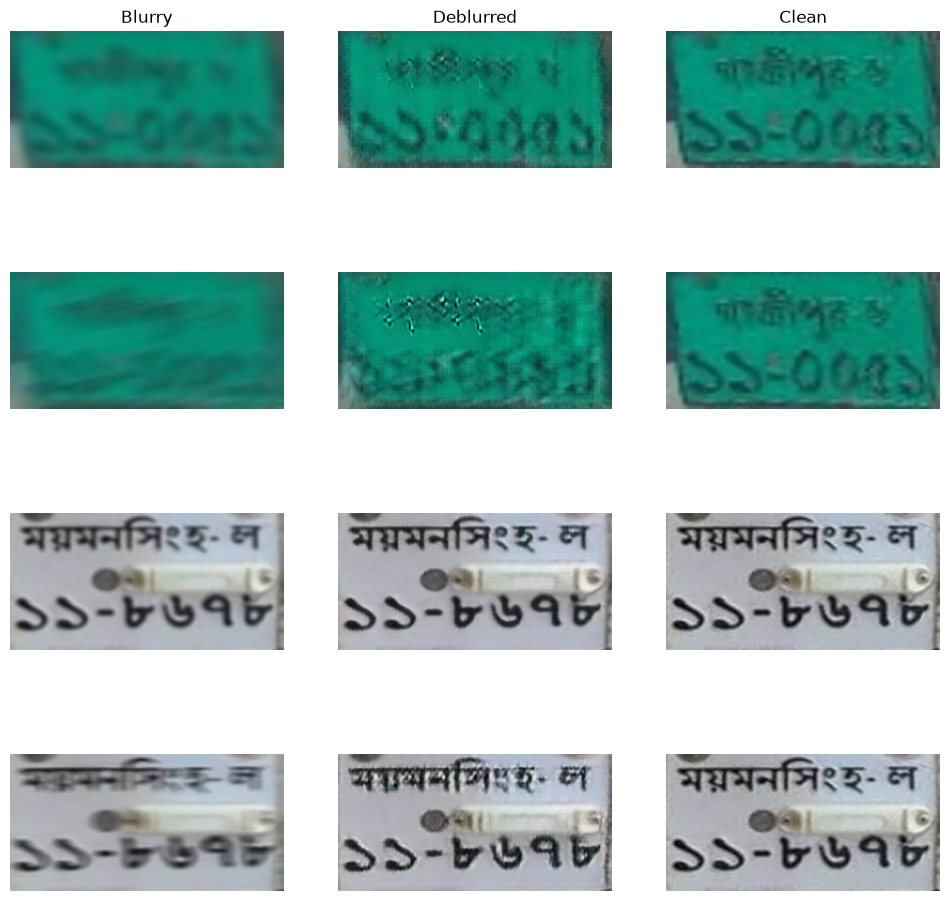

In [15]:
G.eval()
blur, clean = next(iter(val_loader))
with torch.no_grad():
    fake = G(blur.to(device)).clamp(-1, 1).cpu()


def show(t):
    return ((t.permute(1, 2, 0) + 1) / 2).clamp(0, 1).numpy()


n = min(4, blur.size(0))
fig, axes = plt.subplots(n, 3, figsize=(12, 3 * n), squeeze=False)
for i in range(n):
    axes[i][0].imshow(show(blur[i]))
    axes[i][1].imshow(show(fake[i]))
    axes[i][2].imshow(show(clean[i]))
    for j in range(3):
        axes[i][j].axis("off")
axes[0][0].set_title("Blurry")
axes[0][1].set_title("Deblurred")
axes[0][2].set_title("Clean")
plt.show()

Final evaluation with the best weights

In [16]:
G.load_state_dict(torch.load(BEST_PATH, map_location=device))
p, s, m = evaluate(G, val_loader)
p, s, m = p.cpu().numpy(), s.cpu().numpy(), m.cpu().numpy()

is_motion = np.array([os.path.dirname(b) == MOTION_DIR for b, _ in val_pairs])
groups = {"all": np.ones(len(p), dtype=bool), "gaussian": ~is_motion, "motion": is_motion}

for name, mask in groups.items():
    print(f"{name:9s} | PSNR {p[mask].mean():.2f} | SSIM {s[mask].mean():.4f} | MAE {m[mask].mean():.2f}")

C:\Users\Sagar\AppData\Local\Temp\ipykernel_5144\983006772.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  G.load_state_dict(torch.load(BEST_PATH, map_location=device))


all       | PSNR 27.32 | SSIM 0.8477 | MAE 7.80
gaussian  | PSNR 29.43 | SSIM 0.8922 | MAE 6.08
motion    | PSNR 25.21 | SSIM 0.8031 | MAE 9.52
